RhoA-GTP Tilt Angles: 100%|██████████| 1985/1985 [02:13<00:00, 14.87it/s]


97.6096470249318


RhoA-GTP Rotation Angles: 100%|██████████| 1985/1985 [00:10<00:00, 191.84it/s]
/tmp/ipykernel_330246/1627564458.py:189: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if rotation_angles[np.isnan(rotation_angles)] == np.array([np.nan]):


[]


/tmp/ipykernel_330246/1627564458.py:44: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  contour_segments = all_contours.allsegs


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

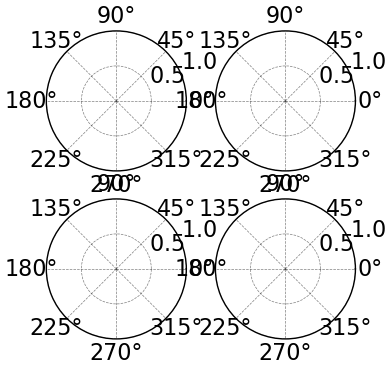

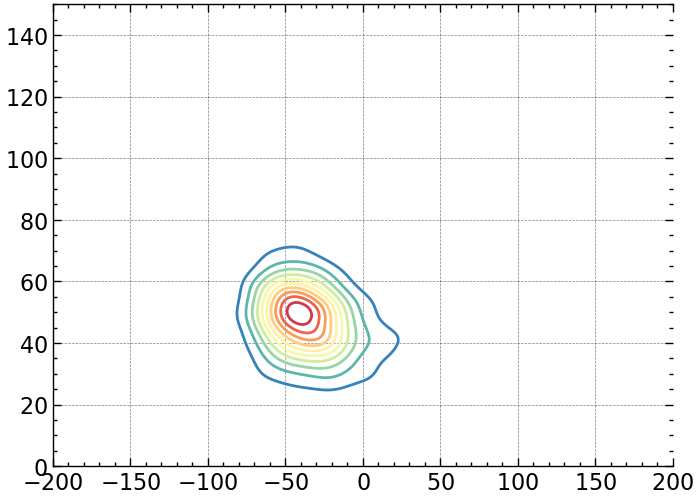

In [ ]:
import MDAnalysis as mda
import numpy as np
import pandas as pd
import seaborn as sns
import nglview as nv
from nglview.contrib.movie import MovieMaker
import matplotlib.pyplot as plt
from MDAnalysis.analysis.distances import dist
import matplotlib.ticker as tkr
import matplotlib.pylab as plb
import math as math
import MDAnalysis.transformations as trn
import scipy as sci
from sklearn.neighbors import KernelDensity
import scienceplots
from tqdm import tqdm
from matplotlib.colors import ListedColormap
from scipy.ndimage import label as nd_label, gaussian_filter, binary_dilation

step = 100

plt.style.use(['science', 'notebook', 'grid'])
u = mda.Universe("rhebgdp/sys.psf", "rhebgdp/cenwrapprod.dcd")
u2 = mda.Universe("/home/chutchins@uthouston.edu/projects/rheb/rhebgtpanalysis/20us/sys.psf", "/home/chutchins@uthouston.edu/projects/rheb/rhebgtpanalysis/20us/cenwrapprod.dcd")
rhou = mda.Universe("/home/chutchins@uthouston.edu/projects/rhoa/rhoagdpanalysis/20us/sys.psf", "/home/chutchins@uthouston.edu/projects/rhoa/rhoagdpanalysis/20us/cenwrapprod.dcd")
rhou2 = mda.Universe("/mnt/nas/chase_projects/rhoa/rhoagtpanalysis/20us/sys.psf", "/mnt/nas/chase_projects/rhoa/rhoagtpanalysis/20us/cenwrapprod.dcd")
contour_dictionary = {}
rotation_angles_dictionary = {}
tilt_angles_dictionary = {}
fig, ax = plt.subplots(nrows=2, ncols=2, subplot_kw={'projection': 'polar'}, figsize=(4,4))
proteins = {u:"Rheb-GDP", u2:"Rheb-GTP", rhou:"RhoA-GDP", rhou2:"RhoA-GTP"}
def get_contour_vertices(data1, data2):
    plt.figure()
    from scipy.stats import gaussian_kde
    data = np.vstack([data1, data2])
    kde = gaussian_kde(data)
    X, Y = np.meshgrid(np.linspace(-200,200, 1000), np.linspace(0,150,1000))

    grid = np.vstack([X.ravel(), Y.ravel()])
    kde_values = kde(grid).reshape(X.shape)

    all_contours = plt.contour(X, Y, kde_values, levels=10, cmap='Spectral_r')

    # Get all contour segments
    contour_segments = all_contours.allsegs

    # Initialize an empty list to store vertices arrays
    contour_x_vertices = []
    contour_y_vertices = []

    # Iterate through the contour segments to get the vertices
    for level_segments in contour_segments:
        for segment in level_segments:
            x_vertices, y_vertices = segment[:, 0], segment[:, 1]
            contour_x_vertices.append(x_vertices)
            contour_y_vertices.append(y_vertices)
    return np.array([contour_x_vertices, contour_y_vertices])

def polar_density_plot(rotationset, tiltset, ax, title, density_threshold=0):
    from scipy.stats import gaussian_kde
    rotation_angles_rad = np.deg2rad(rotationset)
    tilt_angles_rad = np.deg2rad(tiltset)

    data = np.vstack([rotation_angles_rad, tilt_angles_rad])
    kde = gaussian_kde(data)

    # Generate polar grid
    theta, radius = np.mgrid[-np.pi:np.pi:300j, 0:np.deg2rad(130):300j]
    grid_points = np.vstack([theta.ravel(), radius.ravel()])
    kde_values = kde(grid_points).reshape(theta.shape)
    #kde_values /= kde_values.max()
    levels = np.linspace(kde_values.max()*.02, kde_values.max(), 10)
    high_density_levels = levels[levels >= density_threshold * kde_values.max()]
    

    # Create polar contour plot
    base_cmap = plt.cm.Spectral_r
    white_cmap = ListedColormap(['white'])
    new_cmap = ListedColormap(white_cmap(np.linspace(0, 1, 1)).tolist() + base_cmap(np.linspace(0, 1, 255)).tolist())
    ax.set_theta_zero_location('N')
    ax.set_title(r'%s ' % (title), fontsize=12)
    ax.tick_params(axis='x', which='both', labelsize=8, pad=3)
    ax.tick_params(axis='y', which='both', labelsize=8)
    ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])
    ax.set_yticks(np.arange(0,np.deg2rad(130),np.deg2rad(30)))    
    ax.set_yticklabels(np.array(['', '30', '', '', '']))

    ax.set_theta_direction('clockwise')
    ax.grid(linestyle='-', color='black', alpha=.5, zorder=1)
    ax.contourf(theta, radius, kde_values, levels=levels, cmap=new_cmap, zorder=0)
#u3 = mda.Universe("/mnt/nas/chase_projects/rhoa/rhoagtpanalysis/1us/sys.psf", "/mnt/nas/chase_projects/rhoa/rhoagtpanalysis/20us/cenwrapprod.dcd")
unis = [rhou2]
for i in unis:
    if i == u:
        title = "Rheb-GDP"
        ax1 = ax[0,0]
    elif i == u2:
        title = "Rheb-GTP"
        ax1 = ax[0,1]
    elif i == rhou:
        title = "RhoA-GDP"
        ax1 = ax[1,0]
    elif i == rhou2:
        title = "RhoA-GTP"
        ax1 = ax[1,1]

    tiltangles = []
    for ts in tqdm(i.trajectory[::step], desc=f"{title} Tilt Angles"):
        if (i == u) or (i == u2):
            aghelix51 = i.select_atoms("protein and resid 168 and name CA")
            aghelix52 = i.select_atoms("protein and resid 161 and name CA")
            h2com = i.select_atoms("protein and resid 20:27 and backbone").center_of_mass()
            a5vector = aghelix52.positions - aghelix51.positions
        if (i == rhou) or (i == rhou2):
            aghelix51 = i.select_atoms("protein and resid 177 and name CA")
            aghelix52 = i.select_atoms("protein and resid 169 and name CA")
            h2com = i.select_atoms("protein and resid 20:27 and backbone").center_of_mass()
            a5vector = aghelix52.positions - aghelix51.positions        

        membrane_normal = np.array([0, 0, -1])
        vecnorm = np.linalg.norm(a5vector)

        uv1 = np.reshape(a5vector / vecnorm, (3,))
        Do = np.dot(uv1, h2com)
        

        dot = np.clip(np.dot(membrane_normal,uv1), -1, 1)
        angle = np.rad2deg(np.arccos(dot))
        tiltangles.append(angle)
        if angle == min(tiltangles):
            reference_vector = a5vector 
            ref_frame = ts.frame
        Do = np.dot(uv1, h2com)
    tiltangles = np.array(tiltangles)
    tilt_angles_dictionary.update({title:tiltangles})
    print(np.max(tiltangles))
    rotangles = []
    def projection_onto_plane(normal_vector, target_vector):
        dot = np.dot(normal_vector, target_vector)
        square_normal_vector = np.linalg.norm(normal_vector)**2
        projected_vector = target_vector - (dot/square_normal_vector) * normal_vector
        return projected_vector
    def directed_angle(vector1, vector2, normal_vector):
        cross = np.cross(vector1, vector2)
        vector_dot = np.dot(vector1, vector2)
        normal_cross = np.dot(cross, normal_vector)
        sign = np.sign(np.dot(normal_cross, vector_dot))
        angle = sign * np.degrees(np.arccos(vector_dot))

        return angle
        


    tanangles = []
    projzvecs = []
    projavecs = []
    for ts in tqdm(i.trajectory[::step], desc=f"{title} Rotation Angles"):
        if (i == u) or (i == u2):
            aghelix51 = i.select_atoms("protein and resid 168 and name CA")
            aghelix52 = i.select_atoms("protein and resid 161 and name CA").center_of_mass()
            h2com = i.select_atoms("protein and resid 90:91").center_of_mass()
        if (i == rhou) or (i == rhou2):
            aghelix51 = i.select_atoms("protein and resid 177 and name CA")
            aghelix52 = i.select_atoms("protein and resid 169 and name CA").center_of_mass()
            h2com = i.select_atoms("protein and resid 89:93").center_of_mass()            
        a5vector = aghelix52 - aghelix51.center_of_mass()
        h2vector = h2com - aghelix52
        h2vecnorm = h2vector / np.linalg.norm(h2vector)
        vecnorm = np.linalg.norm(a5vector)
        tilt_uv = np.reshape(a5vector / vecnorm, (3,))
        reference_vector = np.reshape(reference_vector, (3,))
        ref_uv = reference_vector / np.linalg.norm(reference_vector)
        ref_uv = np.reshape(ref_uv, (3,))
        a, b, c = tilt_uv
        D = -((a * h2com[0]) + (b * h2com[1]) + (c * h2com[2]))
        plane = np.array([a, b, c, D])
        projected_reference_vec = projection_onto_plane(a5vector, reference_vector) / np.linalg.norm(projection_onto_plane(a5vector, reference_vector))
        projected_h2vector = projection_onto_plane(a5vector, h2vector) / np.linalg.norm(projection_onto_plane(a5vector, h2vector))
        dot_normalcross = np.dot(tilt_uv, np.cross(projected_reference_vec, projected_h2vector))
        dot = np.dot(projected_h2vector, projected_reference_vec)
        rotation_angle = directed_angle(projected_reference_vec, projected_h2vector, tilt_uv)
        if np.isnan(np.array(rotation_angle)) == True:
            rotation_angle = 0 
        projzvecs.append(projected_reference_vec)
        projavecs.append(projected_h2vector)
        rotangles.append(rotation_angle)
    rotation_angles = np.array(rotangles)
    rotation_angles_dictionary.update({title:rotation_angles})
    print(rotation_angles[np.isnan(rotation_angles)])
    if rotation_angles[np.isnan(rotation_angles)] == np.array([np.nan]):
        rotation_angles[np.isnan(rotation_angles)] = 0
    #polar_density_plot(rotation_angles, tiltangles, ax1, title)
    vertices = get_contour_vertices(rotation_angles, tiltangles)
    contour_dictionary.update({title:vertices})
    np.savetxt("RhoA-GTP Redo rotation", rotation_angles)
    np.savetxt("RhoA-GTP Redo Tilt", tiltangles)


In [6]:
np.savetxt("RhoA-GTP Redo rotation", rotation_angles)
np.savetxt("RhoA-GTP Redo Tilt", tiltangles)


/tmp/ipykernel_411554/2942632139.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])


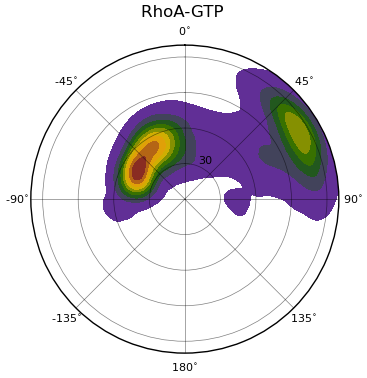

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, subplot_kw={'projection': 'polar'}, figsize=(4,4))
import matplotlib as mpl
import matplotlib.colors as mcolors
import numpy as np
def polar_density_plot(rotationset, tiltset, ax, title, density_threshold=0):
    from scipy.stats import gaussian_kde
    rotation_angles_rad = np.deg2rad(rotationset)
    tilt_angles_rad = np.deg2rad(tiltset)
    colors = [ "#7025B4","#136200", "#F5BD02", "#740F28" , ]
    royal_cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)
    data = np.vstack([rotation_angles_rad, tilt_angles_rad])
    kde = gaussian_kde(data)

    # Generate polar grid
    theta, radius = np.mgrid[-np.pi:np.pi:200j, 0:np.deg2rad(130):200j]
    grid_points = np.vstack([theta.ravel(), radius.ravel()])
    kde_values = kde(grid_points).reshape(theta.shape)
    #kde_values /= kde_values.max()
    #levels = np.linspace(kde_values.max()*.02, kde_values.max(), 10)
    #high_density_levels = levels[levels >= density_threshold * kde_values.max()]
    

    # Create polar contour plot
    base_cmap = plt.cm.Spectral_r
    white_cmap = ListedColormap(['white'])
    new_cmap = ListedColormap(white_cmap(np.linspace(0, 1, 1)).tolist() + base_cmap(np.linspace(0, 1, 255)).tolist())
    ax.set_theta_zero_location('N')
    ax.set_title(r'%s ' % (title), fontsize=12)
    ax.tick_params(axis='x', which='both', labelsize=8, pad=3)
    ax.tick_params(axis='y', which='both', labelsize=8)
    ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])
    ax.set_yticks(np.arange(0,np.deg2rad(130),np.deg2rad(30)))    
    ax.set_yticklabels(np.array(['', '30', '', '', '']))

    ax.set_theta_direction('clockwise')
    ax.grid(linestyle='-', color='black', alpha=.5, zorder=1)
    ax.contourf(theta, radius, kde_values, levels=levels, cmap=royal_cmap, zorder=0)
# rotation_angles = np.loadtxt("RhoA-GTP Redo rotation")
# tilt_angles = np.loadtxt("RhoA-GTP Redo Tilt")
for u in 
polar_density_plot(rotation_angles, tiltangles, ax, title)


# Plotting with smoothed histogram 

/tmp/ipykernel_1915136/423187055.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])


Plotting Rheb_GDP at ax[0, 0]


/tmp/ipykernel_1915136/423187055.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])


Plotting Rheb_GTP at ax[1, 0]


/tmp/ipykernel_1915136/423187055.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])
/tmp/ipykernel_1915136/423187055.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])


Plotting RhoA_GDP at ax[0, 1]
Plotting RhoA_GTP at ax[1, 1]


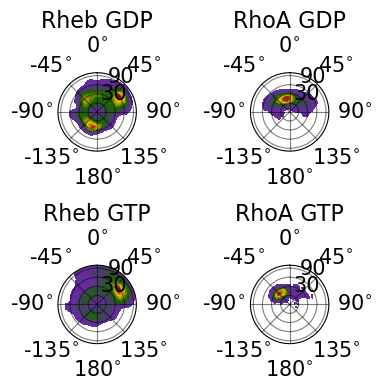

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.ndimage import gaussian_filter
import numpy.ma as ma
import matplotlib.colors as mcolors




def polar_density_histogram_smooth(rotationset, tiltset, ax, title):
    # Convert angles from degrees to radians
    rotation_angles_rad = np.deg2rad(rotationset)
    tilt_angles_rad = np.deg2rad(tiltset)
    
    # Define the number of bins for theta and radius
    num_theta_bins = 360  # 1-degree bins over 360 degrees
    num_radius_bins = 100  # Adjust for desired radial resolution
    
    # Create bins for theta (rotation angles)
    theta_bins = np.linspace(-np.pi, np.pi, num_theta_bins + 1)
    # Create bins for radius (tilt angles)
    radius_bins = np.linspace(0, np.deg2rad(130), num_radius_bins + 1)
    
    # Compute the 2D histogram
    histogram, _, _ = np.histogram2d(
        rotation_angles_rad, tilt_angles_rad, bins=[theta_bins, radius_bins]
    )
    
    # Pad the histogram in theta to handle circularity
    pad_width = 20  # Number of bins to pad on each side
    histogram_padded = np.pad(histogram, ((pad_width, pad_width), (0, 0)), mode='wrap')
    colors = [ "#7025B4","#136200", "#F5BD02", "#740F28" , ]
    royal_cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)
    # Apply Gaussian smoothing with wrap mode in theta
    histogram_smoothed = gaussian_filter(histogram_padded, sigma=(5, 2), mode='wrap')
    
    # Remove the padding
    histogram_smoothed = histogram_smoothed[pad_width:-pad_width, :]  # Shape: (360, 100)
    
    # Transpose the histogram for correct orientation
    histogram_smoothed = histogram_smoothed.T  # Shape: (100, 360)
    
    # Prepare grid for plotting
    theta_centers = (theta_bins[:-1] + theta_bins[1:]) / 2  # Length: 360
    radius_centers = (radius_bins[:-1] + radius_bins[1:]) / 2  # Length: 100
    
    # Generate the meshgrid with default indexing ('xy')
    Theta, Radius = np.meshgrid(theta_centers, radius_centers)
    # Theta.shape: (100, 360)
    # Radius.shape: (100, 360)
    
    # Normalize histogram for better visualization
    histogram_smoothed /= np.max(histogram_smoothed)
    histogram_smoothed = histogram_smoothed.reshape(Theta.shape)
    threshold = 0.00  # Adjust this value as needed (0.02 corresponds to 2%)
    histogram_smoothed[:, 0] = (histogram_smoothed[:, 0] + histogram_smoothed[:, -1]) / 2
    histogram_smoothed[:, -1] = histogram_smoothed[:, 0]

    # Mask the data below the threshold
    masked_data = ma.masked_less(histogram_smoothed, threshold)
    #histogram_smoothed[histogram_smoothed < .02] = np.nan
    # Define levels from the threshold to the maximum
    levels = np.linspace(threshold, 1, 10)
    
    # Create the colormap
    # Plot settings
    ax.set_theta_zero_location('N')
    ax.set_title(title, fontsize=16)
    ax.tick_params(axis='x', which='both', labelsize=15, pad=8.5)
    ax.tick_params(axis='y', which='both', labelsize=15)
    ax.set_xticklabels(['0$^{\circ}$', '45$^{\circ}$', '90$^{\circ}$', '135$^{\circ}$', '180$^{\circ}$', '-135$^{\circ}$', '-90$^{\circ}$', '-45$^{\circ}$'])
    ax.set_yticks(np.deg2rad([0, 30, 60, 90, 120]))
    ax.set_yticklabels(['', '30', '', '90', ''])
    ax.set_theta_direction('clockwise')
    ax.grid(linestyle='-', color='black', alpha=0.5, zorder=1)
    
    # Plot the density contour
    levels = np.linspace(0.02, 1, 11)
    ax.contourf(Theta, Radius, histogram_smoothed, levels=levels, cmap=royal_cmap, zorder=0)
fig, ax = plt.subplots(nrows=2, ncols=2, subplot_kw={'projection': 'polar'}, figsize=(4,4))
systems = ["Rheb_GDP", "Rheb_GTP", "RhoA_GDP", "RhoA_GTP"]# "Rheb_GTP", "RhoA_GDP", "RhoA_GTP"]
titles = ["Rheb GDP", "Rheb GTP", "RhoA GDP", "RhoA GTP" ]#"Rheb GTP", "RhoA GDP", "RhoA GTP"]
n = 0
c = 0
for i, sys in enumerate(systems):
    # Load data
    
    if i > 1:
        c = 1
    if i == 2:
        n = 0

    if sys == "RhoA_GTP":
        rot = np.loadtxt(f"RhoA-GTP Redo rotation")[::1]
        tilt = np.loadtxt(f"RhoA-GTP Redo Tilt")[::1]
    else:
        rot = np.loadtxt(f"tiltandrotation/{sys}rotationangles.txt")[::1]
        tilt = np.loadtxt(f"tiltandrotation/{sys}tiltangles.txt")[::1]
    # Calculate row and column indices
    
    # Plot on the appropriate subplot
    polar_density_histogram_smooth(rot, tilt, ax[n,c], f"{titles[i]}")
    print(f"Plotting {sys} at ax[{n}, {c}]")
    plt.tight_layout()
    
    n =+ 1
    
plt.savefig("tiltandrotation/rhebgdp/GDPtiltandrotation_smooth_histogram.svg", dpi=1000)

In [8]:
for protein, array in rotation_angles_dictionary.items():
    # Replace any special characters in the protein name that might cause issues with the filename
    safe_protein_name = "".join(c if c.isalnum() else "_" for c in protein)
    
    # Create a filename containing the protein name
    filename = f"tiltandrotation/{safe_protein_name}rotationangles.txt"
    
    # Save the numpy array to a text file
    np.savetxt(filename, array, fmt="%.18e", delimiter="\n")
for protein, array in tilt_angles_dictionary.items():
    # Replace any special characters in the protein name that might cause issues with the filename
    safe_protein_name = "".join(c if c.isalnum() else "_" for c in protein)
    
    # Create a filename containing the protein name
    filename = f"tiltandrotation/{safe_protein_name}tiltangles.txt"
    
    # Save the numpy array to a text file
    np.savetxt(filename, array, fmt="%.18e", delimiter="\n")


# Finding the Highest Density Contour of the Rheb-GDP plot. will then be used for the other systems. 


In [9]:
# Vertices of each contour are stored in the contour_dictionary object. This contains the x (rotation) and y (tilt) vertices. The following code can print our the x-y range of the contours of interest, and many other manipulations can be performed on the contour dictionary. 

for i, vertices in enumerate(contour_dictionary["Rheb-GDP"][0]):
    print("Contour {} Rotation Angle Range: {} - {}".format(i, np.min(vertices), np.max(vertices)))
for i, vertices in enumerate(contour_dictionary["Rheb-GDP"][1]):
    print("Contour {} Tilt Angle Range: {} - {}".format(i, np.min(vertices), np.max(vertices)))

Contour 0 Rotation Angle Range: -196.2163442634007 - 193.9236277360845
Contour 1 Rotation Angle Range: -190.8431636722105 - 187.36421588679792
Contour 2 Rotation Angle Range: -187.04680428479253 - 182.05173176735778
Contour 3 Rotation Angle Range: -183.8744683673181 - 80.97647236121819
Contour 4 Rotation Angle Range: 143.62700050505714 - 176.48480061036412
Contour 5 Rotation Angle Range: -180.98883208451065 - -106.73277149874387
Contour 6 Rotation Angle Range: -69.79333299031377 - 31.481930957198156
Contour 7 Rotation Angle Range: 160.92025899811284 - 166.10568843640206
Contour 8 Rotation Angle Range: 35.5375853160639 - 76.68251300348001
Contour 9 Rotation Angle Range: -178.2011879365056 - -118.5892637874584
Contour 10 Rotation Angle Range: -58.40617636419026 - -13.386586877482992
Contour 11 Rotation Angle Range: 39.48878846122704 - 73.42323301502444
Contour 12 Rotation Angle Range: -175.35717060427197 - -128.23316004891348
Contour 13 Rotation Angle Range: 42.85148017211583 - 70.130500

# Rheb-GDP
    Orientation State 1 (calling this contour 10) Rotation Angle Range: -172.25to -137.25 degrees, Tilt angle range = 42.05369446330035 - 57.95728891548795
    Orientation State 2 Rotation angle range (contour 8): -58.5 - -13.5, Tilt angle range:  42.480748167434854 - 63.78465825010274
    Orientation State 3 Rotation angle range (contour 9): 42.85148017211583 - 70.13050022241032, Tilt angle Range = 74.65466729437654 - 98.22761178584824
# Rheb-GTP
    Will Share the same orientation state values as GDP for now, may adjust if necessarry. 

# Calculating Orientation States for RhoA-GDP/GTP
    Since there is only one real state this should not be difficult. 

IndexError: index 8 is out of bounds for axis 1 with size 8

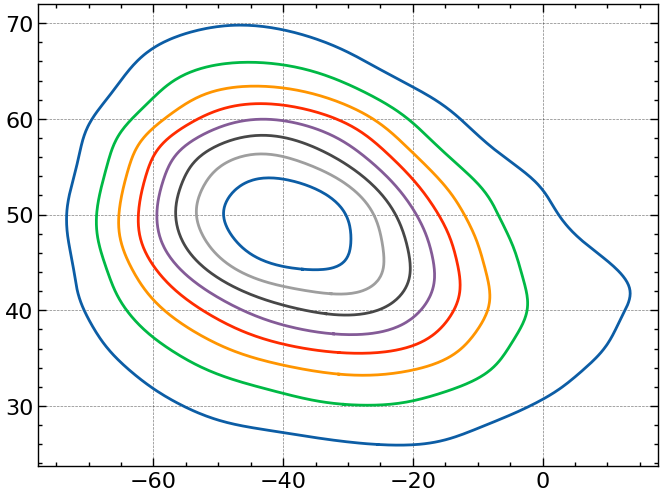

In [43]:
for i in np.arange(0,11,1):
    plt.plot(contour_dictionary["RhoA-GTP"][0,i],contour_dictionary["RhoA-GTP"][1,i])

# RhoA-GDP
    RhoA-GDP Rotation Range = -26.47192862410848 - -2.2617442270808925, Tilt Range = 38.75486744043459 - 51.37626427014072
# RhoA-GTP 
    RhoA-GTP Rotation Range = -49.19595809780249 - -29.550710936806325, Tilt Range = 44.23090340948396 - 53.82954144326615

In [44]:

for i, vertices in enumerate(contour_dictionary["RhoA-GTP"][0]):
    print("Contour {} Rotation Angle Range: {} - {}".format(i, np.min(vertices), np.max(vertices)))
for i, vertices in enumerate(contour_dictionary["RhoA-GTP"][1]):
    print("Contour {} Tilt Angle Range: {} - {}".format(i, np.min(vertices), np.max(vertices)))








Contour 0 Rotation Angle Range: -73.40248386660099 - 13.503266206582895
Contour 1 Rotation Angle Range: -68.80651557446288 - -2.307243856696637
Contour 2 Rotation Angle Range: -65.37349238239999 - -8.132924967534102
Contour 3 Rotation Angle Range: -62.3457921720907 - -12.714803334053286
Contour 4 Rotation Angle Range: -59.47461860168613 - -16.655481692316958
Contour 5 Rotation Angle Range: -56.582691698847505 - -20.402720840366108
Contour 6 Rotation Angle Range: -53.38987097695366 - -24.46380261536609
Contour 7 Rotation Angle Range: -49.19595809780249 - -29.550710936806325
Contour 0 Tilt Angle Range: 25.906934216929915 - 69.7870034344019
Contour 1 Tilt Angle Range: 30.076322813592352 - 65.90723807958553
Contour 2 Tilt Angle Range: 33.20650575196709 - 63.414886920899825
Contour 3 Tilt Angle Range: 35.50313332698662 - 61.5856879109425
Contour 4 Tilt Angle Range: 37.45139716151924 - 59.95892742990627
Contour 5 Tilt Angle Range: 39.496164380114685 - 58.27648438879706
Contour 6 Tilt Angle R

In [8]:
import MDAnalysis as mda
import numpy as np
import pandas as pd
import seaborn as sns
import nglview as nv
from nglview.contrib.movie import MovieMaker
import matplotlib.pyplot as plt
from MDAnalysis.analysis.distances import dist
import matplotlib.ticker as tkr
import matplotlib.pylab as plb
import math as math
import MDAnalysis.transformations as trn
import scipy as sci
from sklearn.neighbors import KernelDensity
import scienceplots
from tqdm import tqdm
from matplotlib.colors import ListedColormap

step = 1

u = mda.Universe("/home/chutchins@uthouston.edu/projects/rheb/rhebgtpanalysis/20us/sys.psf", "/home/chutchins@uthouston.edu/projects/rheb/rhebgtpanalysis/20us/cenwrapprod.dcd")


selection1 = u.select_atoms("resname CYSF and name CA")
selection2 = u.select_atoms("protein and resid 132 and name CA")
zaxis =   np.array([0, 0, 1])
def ts_vectors(selection1, selection2):
    disarray = []
    for ts in tqdm(u.trajectory[::step]):
        global shape
        dis = selection2.positions[0,2] - selection1.positions[0,2]
        disarray.append(dis)
    return np.array(disarray)

a = ts_vectors(selection1, selection2)


100%|██████████| 201850/201850 [03:30<00:00, 957.53it/s] 

[-54.427605, -53.240826, -53.69063, -55.539986, -58.502174, -57.41131, -56.89551, -56.314255, -55.96782, -56.467133, -54.13896, -56.70741, -54.66523, -54.58879, -51.626625, -52.498604, -49.31324, -47.89849, -47.87144, -48.374767, -46.712254, -45.522343, -49.3524, -47.63703, -47.940845, -47.53221, -46.1147, -43.41393, -40.57294, -41.69051, -39.08002, -39.730762, -42.91573, -43.283253, -43.502525, -45.809406, -47.216995, -45.765316, -46.364773, -43.48188, -42.576393, -44.52455, -46.629402, -48.261383, -49.322258, -48.261837, -45.127827, -49.298237, -50.754757, -48.870853, -48.796627, -46.49235, -48.700134, -50.683365, -52.563065, -50.599705, -51.9252, -52.509964, -53.06361, -53.064625, -50.769367, -51.544662, -47.951324, -46.9921, -44.88474, -47.566868, -44.270214, -39.465252, -44.235107, -41.652546, -40.62751, -44.00933, -42.377808, -44.219727, -43.972366, -44.388958, -46.916626, -47.41819, -44.084225, -45.353504, -43.802006, -38.962196, -42.048946, -40.750137, -37.643967, -38.475197, -

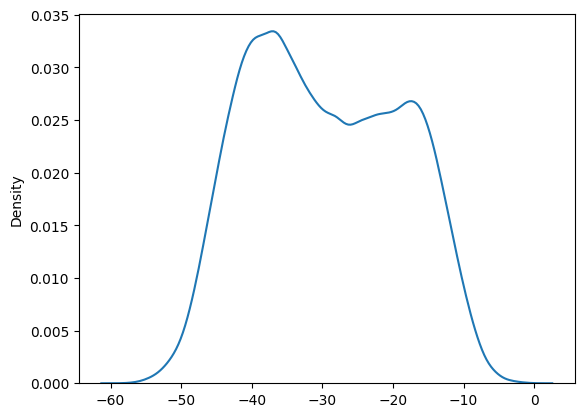

In [14]:

sns.kdeplot(a)


# Binning structures into the orientation state ranges. Starting with Rheb-GDP
    OS1 = Rot(-173.5, -129) , Til(40-58)
    OS2 = Rot(-55.75, -12.5) , Til(43.53235224850456, 61.221846452469805)
    OS3 = Rot(40.73536192846314, 72.49621554027323), Til(71.26588674442509, 98.30698478219433)

In [5]:
import scipy.sparse as sparse
import seaborn as sns
import pandas as pd
import numpy as np
import MDAnalysis as mda 
from MDAnalysis.analysis import contacts
import matplotlib.pyplot as plt
import MDAnalysis.transformations as trn
from tqdm import tqdm

np.set_printoptions(threshold=np.inf)
rhebgdp_rot = np.loadtxt("tiltandrotation/Rheb_GDProtationangles.txt")
rhebgdp_tilt = np.loadtxt("tiltandrotation/Rheb_GDPtiltangles.txt")

rotation_mask = np.logical_and(rhebgdp_rot >= -55, rhebgdp_rot <= -12.5)
tilt_mask = np.logical_and(rhebgdp_tilt >= 43, rhebgdp_tilt <= 61)
combined_mask = (rotation_mask & tilt_mask)

OS1_indices = np.where(combined_mask)
print(OS1_indices[0])
print(len(OS1_indices[0]))

u = mda.Universe("rhebgdp/sys.psf", "rhebgdp/cenwrapprod.dcd")
all_atoms = u.atoms
with mda.Writer("tiltandrotation/rhebgdp/os2.xtc", all_atoms.n_atoms) as W:
    for ts in tqdm(u.trajectory[OS1_indices[0]]):
        W.write(all_atoms)


[  3034   3047   3049   3050   3051   3052   3053   3054   3055   3056
   3057   3058   3059   3064   3068   3071   3074   3075   3076   3077
   3078   3079   3080   3081   3082   3083   3084   3085   3086   3087
   3088   3118   3119   3473   3474   3475   3479   4496   4497   4499
   4501   4502   4503   4504   4506   4507   4519   4520   4523   4524
   4525   4526   4527   4528   4530   4532   4533   4794   4795   4821
   5792   5803   5804   5807   5867   5889   6093   6094   6095   6203
   6559   6560   6561   6562  11883  11887  11893  11895  11896  11897
  11900  11921  11927  11928  11930  11931  11932  11934  11941  11942
  12264  12265  12266  12267  12268  12269  12270  12271  12272  12275
  12276  12277  12278  12279  12280  12281  12282  12283  12284  12285
  12286  12287  12299  12300  12301  12302  12303  12304  12305  12306
  12307  12308  12309  12310  12311  12312  12313  12314  12881  12956
  12978  12985  12986  12987  12988  13015  13020  13027  13029  13032
  1303

/home/chutchins@uthouston.edu/miniconda3/envs/MDenv/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
100%|██████████| 10553/10553 [01:17<00:00, 135.35it/s]


/home/chutchins@uthouston.edu/miniconda3/envs/MDenv/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


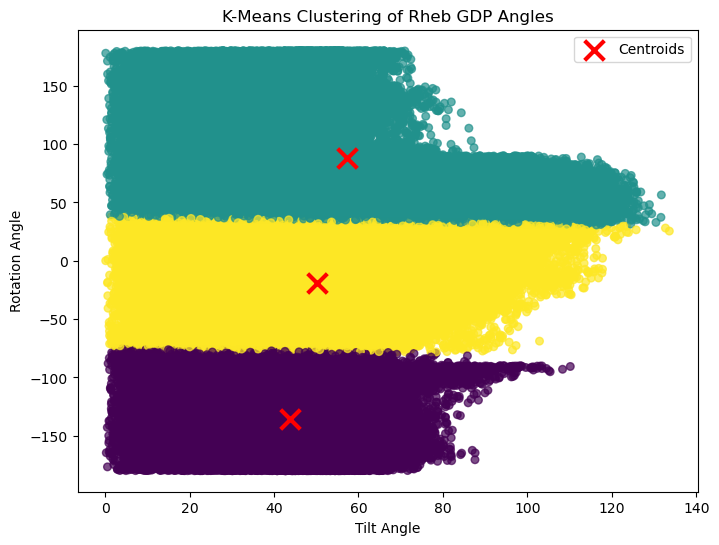

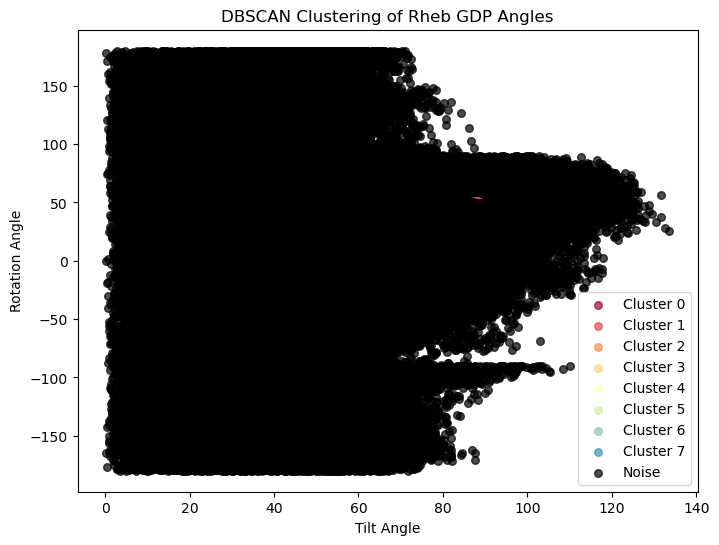

In [7]:
import numpy as np

# Load the data from text files.
rhebgdp_rot = np.loadtxt("tiltandrotation/Rheb_GDProtationangles.txt")
rhebgdp_tilt = np.loadtxt("tiltandrotation/Rheb_GDPtiltangles.txt")

# Combine into a 2D array: each row is [tilt, rotation]
angles = np.column_stack((rhebgdp_tilt, rhebgdp_rot))

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Set the number of clusters to 3.
kmeans = KMeans(n_clusters=3, random_state=42)
labels_km = kmeans.fit_predict(angles)
centers_km = kmeans.cluster_centers_

# Plot the results.
plt.figure(figsize=(8, 6))
scatter = plt.scatter(angles[:, 0], angles[:, 1], c=labels_km, cmap='viridis', s=30, alpha=0.7)
plt.scatter(centers_km[:, 0], centers_km[:, 1], marker='x', color='red', s=200, linewidths=3, label='Centroids')
plt.xlabel("Tilt Angle")
plt.ylabel("Rotation Angle")
plt.title("K-Means Clustering of Rheb GDP Angles")
plt.legend()
plt.show()

from sklearn.cluster import DBSCAN

# Parameters for DBSCAN; adjust eps and min_samples as needed.
dbscan = DBSCAN(eps=1, min_samples=100)
labels_db = dbscan.fit_predict(angles)

# Get unique labels (clusters) and assign colors.
unique_labels = set(labels_db)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

plt.figure(figsize=(8, 6))
for k, col in zip(unique_labels, colors):
    # Label -1 in DBSCAN is considered noise.
    if k == -1:
        col = 'black'
        label_name = "Noise"
    else:
        label_name = f"Cluster {k}"
    class_member_mask = (labels_db == k)
    xy = angles[class_member_mask]
    plt.scatter(xy[:, 0], xy[:, 1], c=[col], s=30, label=label_name, alpha=0.7)

plt.xlabel("Tilt Angle")
plt.ylabel("Rotation Angle")
plt.title("DBSCAN Clustering of Rheb GDP Angles")
plt.legend()
plt.show()


In [2]:
rhebgdp_rot = np.loadtxt("tiltandrotation/Rheb_GDProtationangles.txt")
rhebgdp_tilt = np.loadtxt("tiltandrotation/Rheb_GDPtiltangles.txt")

rotation_mask = np.logical_and(rhebgdp_rot >= -55.75, rhebgdp_rot <= -12.5)
tilt_mask = np.logical_and(rhebgdp_tilt >= 43, rhebgdp_tilt <= 61)

combined_mask = np.logical_and(rotation_mask, tilt_mask)

OS2_indices = np.where(combined_mask)
print(OS2_indices[0] * 100)
u = mda.Universe("rhebgdp/sys.psf", "rhebgdp/cenwrapprod.dcd")
all_atoms = u.atoms
with mda.Writer("tiltandrotation/rhebgdp/os2.dcd", all_atoms.n_atoms) as W:
    for ts in tqdm(u.trajectory[OS2_indices[0]]):
        W.write(all_atoms)

[  303400   304700   304900   305000   305100   305200   305300   305400
   305500   305600   305700   305800   305900   306400   306800   307100
   307400   307500   307600   307700   307800   307900   308000   308100
   308200   308300   308400   308500   308600   308700   308800   311800
   311900   347300   347400   347500   347900   449600   449700   449900
   450100   450200   450300   450400   450600   450700   451900   452000
   452300   452400   452500   452600   452700   452800   453000   453200
   453300   479400   479500   482100   579200   579300   580300   580400
   580700   586600   586700   588900   609300   609400   609500   620100
   620200   620300   655900   656000   656100   656200  1188300  1188700
  1189200  1189300  1189500  1189600  1189700  1190000  1192100  1192700
  1192800  1193000  1193100  1193200  1193400  1194100  1194200  1226400
  1226500  1226600  1226700  1226800  1226900  1227000  1227100  1227200
  1227500  1227600  1227700  1227800  1227900  1228

100%|██████████| 10737/10737 [00:45<00:00, 233.72it/s]


In [16]:
rhebgdp_rot = rotation_angles_dictionary["Rheb-GDP"]
rhebgdp_tilt = tilt_angles_dictionary["Rheb-GDP"]

rotation_mask = np.logical_and(rhebgdp_rot >= 40, rhebgdp_rot <= 72)
tilt_mask = np.logical_and(rhebgdp_tilt >= 71, rhebgdp_tilt <= 98)

combined_mask = np.logical_and(rotation_mask, tilt_mask)

OS3_indices = np.where(combined_mask)
print(OS3_indices[0] * 100)
u = mda.Universe("rhebgdp/sys.psf", "rhebgdp/cenwrapprod.dcd")
all_atoms = u.atoms
with mda.Writer("tiltandrotation/rhebgdp/os3.dcd", all_atoms.n_atoms) as W:
    for ts in tqdm(u.trajectory[OS3_indices[0]]):
        W.write(all_atoms)

[  286500   286700   287000   287200   332500   333000   352100   356200
   356300   356400   357500   357700   357800   357900   358200   358300
   358400   359400   359500   359700   359800   359900   360000   360100
   360200   360900   361000   361100   363100   363200   364000   375500
   376200   376300   376400   376500   376600   376800   377200   377300
   377400   377500   377600   377700   377800   377900   378000   378100
   378200   378300   378400   378500   378600   378700   378800   378900
   379000   379100   379200   379300   379400   379500   379600   379700
   379800   379900   380000   380100   380200   380300   380400   380500
   380600   380700   380800   380900   381000   381100   381200   381300
   381400   381500   381600   381700   381800   381900   382000   382100
   382200   382300   382400   382500   382600   382700   382800   382900
   383000   383100   383200   383300   383400   383600   383700   383800
   383900   384100   384200   384300   384400   384

100%|██████████| 15748/15748 [01:07<00:00, 233.14it/s]


/tmp/ipykernel_736892/308820935.py:27: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  averaged_df = df.groupby(mapping, axis=1).mean()
/home/chutchins@uthouston.edu/miniconda3/envs/MDenv/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/chutchins@uthouston.edu/miniconda3/envs/MDenv/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


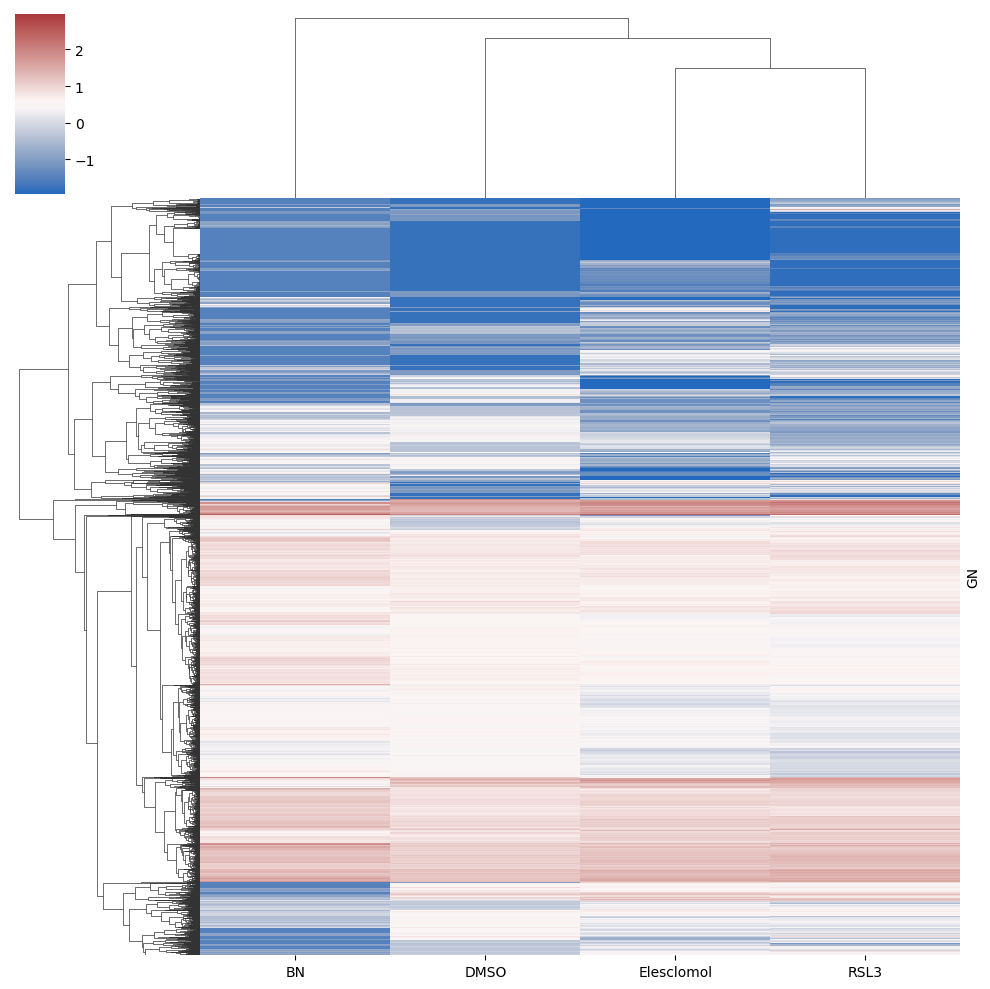

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_excel("1023-Tracy Luu.xlsx", header=0, index_col=0)

df
# Map each column to its treatment condition
mapping = {
    'BN': 'BN',
    'Unnamed: 2': 'BN',
    'Unnamed: 3': 'BN',
    'DMSO': 'DMSO',
    'Unnamed: 5': 'DMSO',
    'Unnamed: 6': 'DMSO',
    'RSL3': 'RSL3',
    'Unnamed: 8': 'RSL3',
    'Unnamed: 9': 'RSL3',
    'Elesclomol': 'Elesclomol',
    'Unnamed: 11': 'Elesclomol',
    'Unnamed: 12': 'Elesclomol'
}

# Group by the mapping along the columns and take the mean
averaged_df = df.groupby(mapping, axis=1).mean()


scaled_data = (averaged_df - np.mean(averaged_df, axis=0)) / np.std(averaged_df, axis=0)

sns.clustermap(scaled_data, method='average', cmap='vlag', row_cluster=True, yticklabels=False)

plt.savefig("clustermap.png", dpi=600)

In [6]:
df

,BN,BN,BN,DMSO,DMSO,DMSO,RSL3,RSL3,RSL3,Elesclomol,Elesclomol,Elesclomol
GN,,,,,,,,,,,,
PARVB,11.000000,11.000000,11.000000,16.167046,16.043604,11.000000,11.000000,13.492729,11.000000,11.000000,11.000000,11.000000
UGDH,11.000000,11.000000,11.000000,11.000000,16.072572,15.697646,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000
SARS1,11.000000,11.000000,11.000000,11.000000,11.000000,16.114535,14.334134,15.464259,15.621680,11.000000,11.000000,11.000000
COQ10B,11.000000,11.000000,11.000000,16.571827,16.304726,16.070834,11.000000,15.124202,14.825903,11.000000,16.222644,11.000000
MEGF8,11.000000,11.000000,11.000000,11.000000,16.072070,15.893349,11.000000,11.000000,11.000000,11.000000,15.727389,11.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
ACTBL2,18.866708,18.474962,19.948394,19.847201,20.054032,20.824676,20.905715,20.966417,21.146206,21.747565,21.147499,21.635016
ANXA2,19.276418,18.794413,19.411530,20.517716,20.672481,20.602519,21.448564,21.086407,21.303515,21.265953,20.518627,20.948390
ACTG1,18.997400,18.598532,19.888907,20.124145,20.306468,20.913281,21.060753,21.071058,21.197479,21.797755,20.966310,21.710310
